<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/question_15_quantum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install pennylane scikit-learn pandas numpy matplotlib seaborn torch scipy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 89.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 61.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 87.9 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [2]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pennylane as qml
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries imported successfully!")
print("PennyLane:", qml.__version__)
print("PyTorch:", torch.__version__)


All libraries imported successfully!
PennyLane: 0.45.1
PyTorch: 2.14.1+cpu


In [4]:

print("Files in Google Colab:")

print(os.listdir('/content'))

assert os.path.exists('/content/train.csv'), "train.csv not found!"
assert os.path.exists('/content/test.csv'), "test.csv not found!"

print("Both dataset files are available!")



Files in Google Colab:
['.config', 'sample_submission.csv', 'test.csv', 'train.csv', 'sample_data']
Both dataset files are available!


In [5]:

train = pd.read_csv('/content/train.csv')
test = pd.read_csv('/content/test.csv')

X = train.drop('label', axis=1).values
y = train['label'].values

X = X.astype('float32') / 255.0

print("Training dataset:", X.shape)
print("Testing dataset:", test.shape)

print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

print("Dataset loaded successfully!")


Training dataset: (8026, 784)
Testing dataset: (10340, 784)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Dataset loaded successfully!


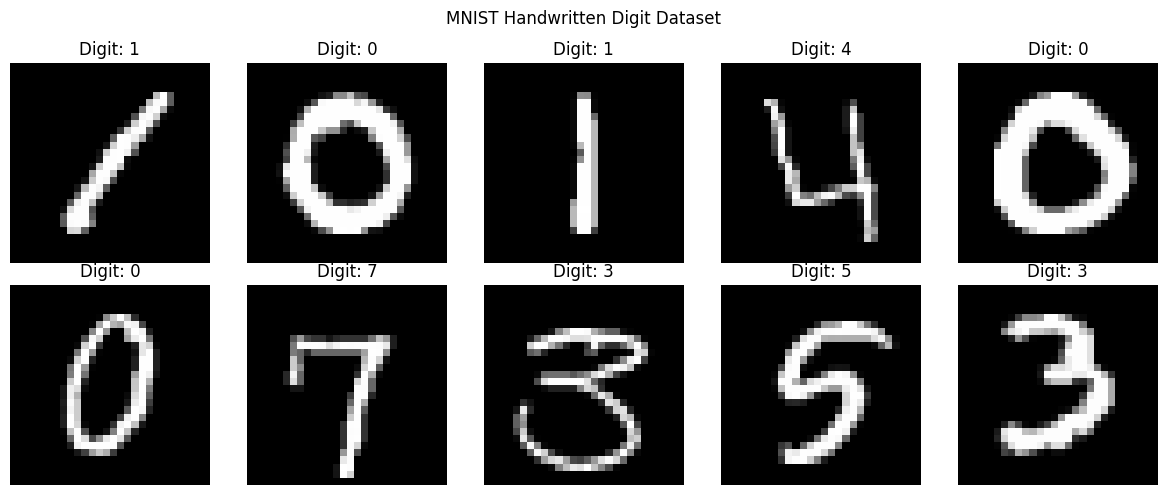

In [6]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X[i].reshape(28, 28)

    plt.imshow(image, cmap='gray')
    plt.title(f"Digit: {y[i]}")
    plt.axis('off')

plt.suptitle("MNIST Handwritten Digit Dataset")
plt.tight_layout()
plt.show()


In [7]:

X_small, _, y_small, _ = train_test_split(
    X,
    y,
    train_size=2000,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_small,
    y_small,
    test_size=0.2,
    stratify=y_small,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


Training samples: 1600
Validation samples: 400


In [8]:

pca = PCA(n_components=4, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)

scaler = MinMaxScaler(
    feature_range=(0, np.pi)
)

X_train_quantum = scaler.fit_transform(X_train_pca)
X_val_quantum = scaler.transform(X_val_pca)

print("Quantum training data:", X_train_quantum.shape)
print("Quantum validation data:", X_val_quantum.shape)

print(
    "PCA explained variance:",
    pca.explained_variance_ratio_.sum()
)


Quantum training data: (1600, 4)
Quantum validation data: (400, 4)
PCA explained variance: 0.28648734


In [9]:

n_qubits = 4
n_layers = 2

dev = qml.device(
    "default.qubit",
    wires=n_qubits
)

print("Quantum simulator created!")
print("Number of qubits:", n_qubits)
print("Number of quantum layers:", n_layers)


Quantum simulator created!
Number of qubits: 4
Number of quantum layers: 2


In [10]:

@qml.qnode(
    dev,
    interface="torch",
    diff_method="backprop"
)
def quantum_circuit(inputs, weights):

    # Encode image features
    qml.AngleEmbedding(
        inputs,
        wires=range(n_qubits),
        rotation="Y"
    )

    # Trainable quantum layers
    qml.StronglyEntanglingLayers(
        weights,
        wires=range(n_qubits)
    )

    # Measure quantum probabilities
    return qml.probs(wires=range(n_qubits))


weight_shapes = {
    "weights": (n_layers, n_qubits, 3)
}

print("Quantum circuit designed successfully!")


Quantum circuit designed successfully!


In [11]:

class QuantumDigitClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

    def forward(self, x):

        probabilities = self.quantum(x)

        # Select 10 outcomes for 10 digit classes
        probabilities = probabilities[:, :10]

        # Normalize selected probabilities
        probabilities = probabilities / (
            probabilities.sum(dim=1, keepdim=True) + 1e-8
        )

        return torch.log(probabilities + 1e-8)


model = QuantumDigitClassifier()

print(model)
print("Quantum classifier created successfully!")


QuantumDigitClassifier(
  (quantum): <Quantum Torch Layer: func=quantum_circuit>
)
Quantum classifier created successfully!


In [12]:

X_train_tensor = torch.tensor(
    X_train_quantum,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_val_quantum,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

print("Training data prepared!")
print("Number of training batches:", len(loader))


Training data prepared!
Number of training batches: 50


In [13]:

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

criterion = nn.NLLLoss()

epochs = 5
training_start = time.perf_counter()

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for inputs, labels in loader:

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(loader)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Loss: {average_loss:.4f}"
    )

training_time = time.perf_counter() - training_start

print("\nTraining completed!")
print(f"Total training time: {training_time:.2f} seconds")


Epoch 1/5 - Loss: 2.4835
Epoch 2/5 - Loss: 2.2705
Epoch 3/5 - Loss: 2.1502
Epoch 4/5 - Loss: 2.0781
Epoch 5/5 - Loss: 2.0301

Training completed!
Total training time: 5.00 seconds


In [14]:

model.eval()

inference_start = time.perf_counter()

with torch.no_grad():
    outputs = model(X_val_tensor)
    probabilities = torch.exp(outputs)
    predictions = torch.argmax(outputs, dim=1).numpy()

inference_time = time.perf_counter() - inference_start

accuracy = accuracy_score(y_val, predictions)

balanced_acc = balanced_accuracy_score(
    y_val, predictions
)

macro_f1 = f1_score(
    y_val, predictions,
    average='macro'
)

print("========== CLASSIFICATION RESULTS ==========")

print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

print(f"Inference Time: {inference_time:.6f} seconds")


========== CLASSIFICATION RESULTS ==========
Accuracy: 0.2375
Balanced Accuracy: 0.2327
Macro F1: 0.1931
Inference Time: 0.031504 seconds


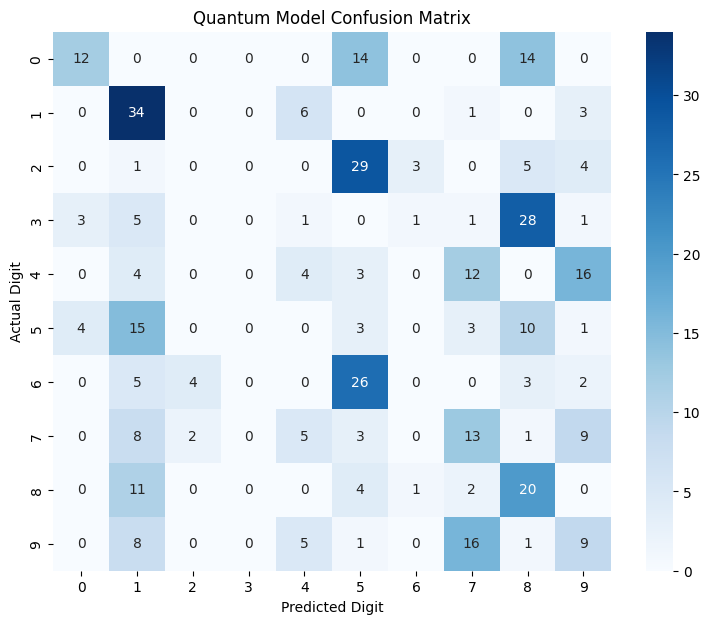

In [15]:

cm = confusion_matrix(
    y_val,
    predictions,
    labels=np.arange(10)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Quantum Model Confusion Matrix")

plt.show()


In [16]:

binary_mask = np.isin(y_val, [0, 1])

y_binary = y_val[binary_mask]

binary_probs = probabilities.numpy()[binary_mask]

positive_probs = (
    binary_probs[:, 1] /
    (
        binary_probs[:, 0] +
        binary_probs[:, 1] + 1e-8
    )
)

binary_auc = roc_auc_score(
    y_binary,
    positive_probs
)

print("Binary classes: 0 and 1")
print(f"Binary AUROC: {binary_auc:.4f}")


Binary classes: 0 and 1
Binary AUROC: 0.9636


In [17]:

number_of_qubits = 4
number_of_layers = 2
shots = None  # Analytic simulator

training_batches = len(loader)

forward_evaluations = epochs * training_batches

inference_evaluations = len(X_val_tensor)

print("========== QUANTUM COST ANALYSIS ==========")

print("Number of qubits:", number_of_qubits)

print("Ansatz layers:", number_of_layers)

print("Shots:", shots)

print("Training forward batch evaluations:",
      forward_evaluations)

print("Validation samples:", inference_evaluations)

print(f"Training time: {training_time:.4f} seconds")

print(f"Inference time: {inference_time:.6f} seconds")

print("Simulator: PennyLane default.qubit")


========== QUANTUM COST ANALYSIS ==========
Number of qubits: 4
Ansatz layers: 2
Shots: None
Training forward batch evaluations: 250
Validation samples: 400
Training time: 4.9975 seconds
Inference time: 0.031504 seconds
Simulator: PennyLane default.qubit


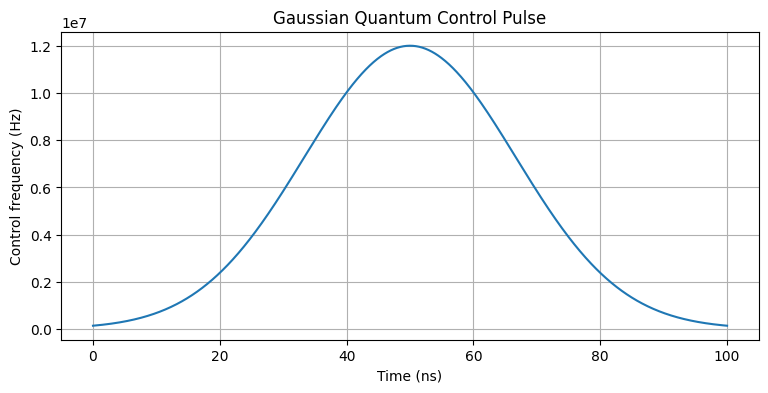

Pulse duration: 100.0 ns


In [18]:

from scipy.linalg import expm

# Pulse parameters
pulse_duration = 100e-9  # 100 nanoseconds
number_of_steps = 1000

dt = pulse_duration / number_of_steps

time_axis = np.linspace(
    0,
    pulse_duration,
    number_of_steps
)

sigma = pulse_duration / 6
center = pulse_duration / 2

pulse = np.exp(
    -((time_axis - center) ** 2) / (2 * sigma ** 2)
)

# Normalize pulse area to pi rotation
pulse = pulse * (
    np.pi / (np.sum(pulse) * dt)
)

plt.figure(figsize=(9, 4))
plt.plot(time_axis * 1e9, pulse / (2 * np.pi))
plt.xlabel("Time (ns)")
plt.ylabel("Control frequency (Hz)")
plt.title("Gaussian Quantum Control Pulse")
plt.grid()
plt.show()

print("Pulse duration:", pulse_duration * 1e9, "ns")


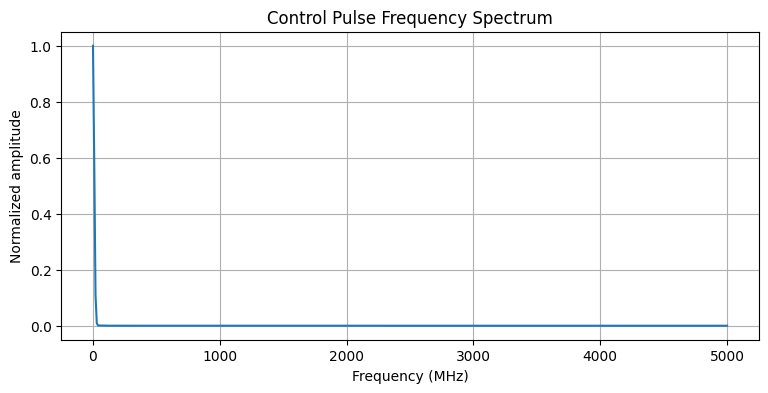

Estimated pulse bandwidth: 10.0 MHz


In [19]:

sampling_frequency = 1 / dt

frequencies = np.fft.rfftfreq(
    number_of_steps,
    d=dt
)

spectrum = np.abs(
    np.fft.rfft(pulse)
)

spectrum = spectrum / (spectrum.max() + 1e-12)

# Find full width at half maximum
indices = np.where(spectrum >= 0.5)[0]

bandwidth = (
    frequencies[indices[-1]] -
    frequencies[indices[0]]
)

plt.figure(figsize=(9, 4))

plt.plot(
    frequencies / 1e6,
    spectrum
)

plt.xlabel("Frequency (MHz)")
plt.ylabel("Normalized amplitude")
plt.title("Control Pulse Frequency Spectrum")
plt.grid()
plt.show()

print(
    "Estimated pulse bandwidth:",
    bandwidth / 1e6,
    "MHz"
)


Noise: 0% | Fidelity: 1.000000
Noise: 1% | Fidelity: 1.000000
Noise: 5% | Fidelity: 0.999991
Noise: 10% | Fidelity: 0.999963
Noise: 20% | Fidelity: 0.999850


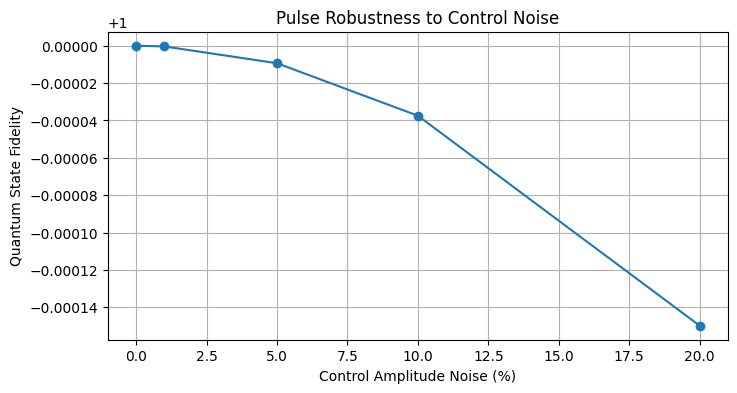

In [20]:

# Pauli X matrix
X_gate = np.array([
    [0, 1],
    [1, 0]
], dtype=complex)

# Initial quantum state |0>
initial_state = np.array(
    [1, 0],
    dtype=complex
)

# Target state after pi rotation: |1>
target_state = np.array(
    [0, 1],
    dtype=complex
)

def simulate_pulse(amplitude_noise=0.0):

    state = initial_state.copy()

    rng = np.random.default_rng(42)

    for amplitude in pulse:

        noisy_amplitude = amplitude * (
            1 + rng.normal(0, amplitude_noise)
        )

        H = 0.5 * noisy_amplitude * X_gate

        U = expm(-1j * H * dt)

        state = U @ state

    fidelity = abs(
        np.vdot(target_state, state)
    ) ** 2

    return float(fidelity)


noise_levels = [0, 0.01, 0.05, 0.10, 0.20]

fidelities = []

for noise in noise_levels:

    fidelity = simulate_pulse(noise)

    fidelities.append(fidelity)

    print(
        f"Noise: {noise*100:.0f}% | "
        f"Fidelity: {fidelity:.6f}"
    )

plt.figure(figsize=(8, 4))

plt.plot(
    np.array(noise_levels) * 100,
    fidelities,
    marker='o'
)

plt.xlabel("Control Amplitude Noise (%)")
plt.ylabel("Quantum State Fidelity")
plt.title("Pulse Robustness to Control Noise")
plt.grid()
plt.show()


In [21]:

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Binary AUROC",
        "Pulse Duration (ns)",
        "Control Bandwidth (MHz)",
        "Noiseless Pulse Fidelity",
        "20% Noise Pulse Fidelity",
        "Number of Qubits",
        "Ansatz Layers",
        "Training Time (seconds)",
        "Inference Time (seconds)"
    ],

    "Result": [
        accuracy,
        balanced_acc,
        macro_f1,
        binary_auc,
        pulse_duration * 1e9,
        bandwidth / 1e6,
        fidelities[0],
        fidelities[-1],
        number_of_qubits,
        number_of_layers,
        training_time,
        inference_time
    ]
})

display(results)


,Metric,Result
0,Accuracy,0.237500
1,Balanced Accuracy,0.232701
2,Macro F1,0.193147
3,Binary AUROC,0.963636
4,Pulse Duration (ns),100.000000
5,Control Bandwidth (MHz),10.000000
6,Noiseless Pulse Fidelity,1.000000
7,20% Noise Pulse Fidelity,0.999850
8,Number of Qubits,4.000000
9,Ansatz Layers,2.000000
